# **60 Batik Nitik Classifier**

- Name: Ricky Fadel M
- NIM: 19/446533/TK/49638
- Prodi: Teknik Fisika

Import packages

In [1]:
import os
import sys
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

Set Hyperparameters

In [2]:
EPOCHS = 25
BATCH_SIZE_TRAIN = 64
LEARNING_RATE = 0.001
DROPOUT_RATE = 0.2
FC_HIDDEN_LAYER_NEURON = 512

Set project dynamic values

In [3]:
EXPERIMENT_NAME = 'nitik_1_512_neuron'
BATCH_SIZE_VALIDATION = 128
BATCH_SIZE_TEST = 128

Connect to Google Drive

In [4]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


**Set** *source* path on `Drive` & *data* on this project path

In [5]:
SOURCE_DIR = '/content/drive/My Drive/Datasets/nitik960-aug-tiled-ok'
DATA_DIR = '/content/batik'

Function: Split data

In [6]:
from shutil import copyfile

def split_data(SOURCE_DIRS, TRAINING_DIR, VALIDATION_DIR, TEST_DIR, SPLIT_SIZE_3):
    non_zero_files = []
    img_count = 0

    for SOURCE_DIR in SOURCE_DIRS:
        list_dir = os.listdir(SOURCE_DIR)

        random.shuffle(list_dir)

        for fname in list_dir:
            file_path = os.path.join(SOURCE_DIR, fname)
            if os.path.isfile(file_path) and os.path.getsize(file_path) != 0:
                non_zero_files.append((SOURCE_DIR, fname))
            else:
                print(f"{fname} is zero length, ignoring.")

    total_files = len(non_zero_files)
    train_split_index = int(SPLIT_SIZE_3[0] * total_files)
    validation_split_index = train_split_index + int(SPLIT_SIZE_3[1] * total_files)

    train_files = non_zero_files[:train_split_index]
    validation_files = non_zero_files[train_split_index:validation_split_index]
    test_files = non_zero_files[validation_split_index:]

    for source_dir, fname in train_files:
        source_path = os.path.join(source_dir, fname)
        destination_path = os.path.join(TRAINING_DIR, fname)
        copyfile(source_path, destination_path)
        img_count += 1

    for source_dir, fname in validation_files:
        source_path = os.path.join(source_dir, fname)
        destination_path = os.path.join(VALIDATION_DIR, fname)
        copyfile(source_path, destination_path)
        img_count += 1

    for source_dir, fname in test_files:
        source_path = os.path.join(source_dir, fname)
        destination_path = os.path.join(TEST_DIR, fname)
        copyfile(source_path, destination_path)
        img_count += 1

    return img_count

Function: Make class dirs. (`train`, `val`, `test`) in this project

In [7]:
def create_directories(base_dir, class_name):
    TRAINING_DIR = os.path.join(base_dir, 'train', class_name)
    VALIDATION_DIR = os.path.join(base_dir, 'validation', class_name)
    TEST_DIR = os.path.join(base_dir, 'test', class_name)

    os.makedirs(TRAINING_DIR, exist_ok=True)
    os.makedirs(VALIDATION_DIR, exist_ok=True)
    os.makedirs(TEST_DIR, exist_ok=True)

    return TRAINING_DIR, VALIDATION_DIR, TEST_DIR

Function: Move samples after split by `split_data()`

In [8]:
def process_all_classes(base_source_dir, base_target_dir, split_size):
    class_dirs = [d for d in os.listdir(base_source_dir) if os.path.isdir(os.path.join(base_source_dir, d))]
    total_img_count = 0

    for class_name in class_dirs:
        SOURCE_DIRS = [os.path.join(base_source_dir, class_name)]
        TRAINING_DIR, VALIDATION_DIR, TEST_DIR = create_directories(base_target_dir, class_name)

        img_count = split_data(SOURCE_DIRS, TRAINING_DIR, VALIDATION_DIR, TEST_DIR, split_size)
        print(f"Finished processing -> {class_name}: ({img_count})")
        total_img_count += img_count

    print(f"Total image: {total_img_count}")

Split the dataset

In [9]:
SPLIT_SIZE = (0.75, 0.15, 0.1)

process_all_classes(SOURCE_DIR, DATA_DIR, SPLIT_SIZE)

Finished processing -> Cinde Wilis: (224)
Finished processing -> Kawung Nitik: (224)
Finished processing -> Kemukus: (224)
Finished processing -> Brendhi: (224)
Finished processing -> Jayakirana: (224)
Finished processing -> Cakar Ayam: (224)
Finished processing -> Arumdalu: (224)
Finished processing -> Klampok Arum: (224)
Finished processing -> Jayakusuma: (224)
Finished processing -> Gedhangan: (224)
Finished processing -> Sekar Dangan: (233)
Finished processing -> Sekar Andhong: (224)
Finished processing -> Kuncup Kanthil: (224)
Finished processing -> Mawur: (224)
Finished processing -> Rengganis: (224)
Finished processing -> Sekar Blimbing: (224)
Finished processing -> Sekar Cengkeh: (224)
Finished processing -> Sari Mulat: (224)
Finished processing -> Sekar Dhuku: (224)
Finished processing -> Manggar: (224)
Finished processing -> Sekar Gambir: (254)
Finished processing -> Sekar Duren: (224)
Finished processing -> Krawitan: (224)
Finished processing -> Sekar Gudhe: (224)
Finished p

Function: display images

In [10]:
import os
import random
import matplotlib.pyplot as plt

def viz_random_samples_each_sets(set_directory, N=5):
  subsets = ['train', 'validation', 'test']

  fig, axs = plt.subplots(len(subsets), N + 1, figsize=(N*3 + 1, len(subsets)*3),
                          gridspec_kw={'width_ratios': [0.2] + [1]*N})

  plt.subplots_adjust(wspace=0.1, hspace=0.3)

  for i, subset in enumerate(subsets):
      subset_dir = os.path.join(set_directory, subset)

      axs[i, 0].text(0.5, 0.5, subset.capitalize(), ha='center', va='center', rotation=0, fontsize=12)
      axs[i, 0].axis('off')

      for j in range(1, N + 1):
          class_dirs = [d for d in os.listdir(subset_dir) if os.path.isdir(os.path.join(subset_dir, d))]
          if not class_dirs:
              continue

          selected_class = random.choice(class_dirs)
          selected_class_dir = os.path.join(subset_dir, selected_class)
          img_files = os.listdir(selected_class_dir)

          if img_files:
              img_name = random.choice(img_files)
              img_path = os.path.join(selected_class_dir, img_name)
              img = plt.imread(img_path)
              axs[i, j].imshow(img)
              axs[i, j].axis('off')
          else:
              continue

  plt.show()

Viz: Display random samples

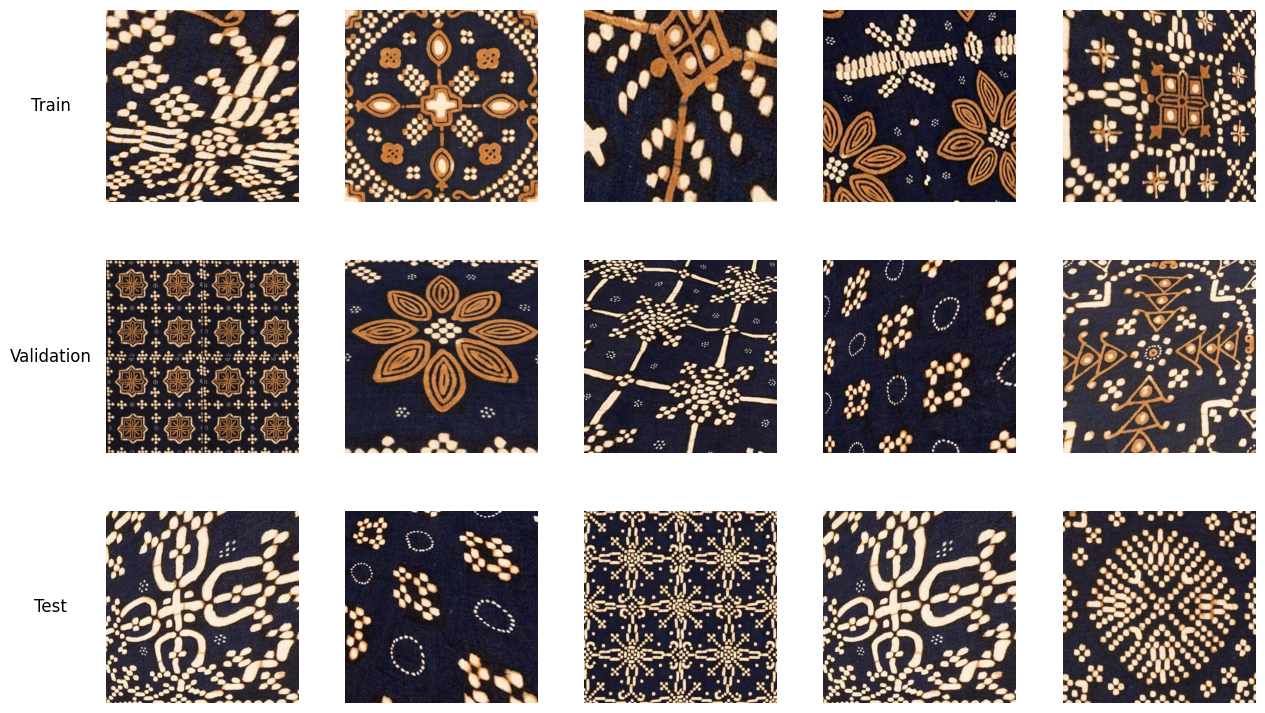

In [11]:
viz_random_samples_each_sets(DATA_DIR)

Set *train*, *test*, & *validation* dir. as variables

In [12]:
TRAIN_DIR = os.path.join(DATA_DIR, 'train')
VALIDATION_DIR = os.path.join(DATA_DIR, 'validation')
TEST_DIR = os.path.join(DATA_DIR, 'test')

Explore: check samples *shape*

In [13]:
from tensorflow.keras.utils import load_img, img_to_array

sample_class_path = os.path.join(TRAIN_DIR, os.listdir(TRAIN_DIR)[0])
sample_img_path = os.path.join(sample_class_path, os.listdir(sample_class_path)[0])

sample_img = load_img(sample_img_path)
sample_img_arr = img_to_array(sample_img)

print(f"Samples shape: {sample_img_arr.shape}")

Samples shape: (512, 512, 3)


Function: Count image in sets

In [14]:
def count_samples_in_sets(base_dir):
    sets = ['train', 'validation', 'test']
    train_count, validation_count, test_count = 0, 0, 0

    for set_name in sets:
        set_dir = os.path.join(base_dir, set_name)
        total_images = 0

        if os.path.isdir(set_dir):
            class_dirs = [os.path.join(set_dir, d) for d in os.listdir(set_dir) if os.path.isdir(os.path.join(set_dir, d))]
            for class_dir in class_dirs:
                total_images += len([img for img in os.listdir(class_dir) if img.lower().endswith(('.png', '.jpg', '.jpeg'))])

        if set_name == 'train':
            train_count = total_images
        elif set_name == 'validation':
            validation_count = total_images
        elif set_name == 'test':
            test_count = total_images

    return train_count, validation_count, test_count

Explore: amount of samples in each set

In [15]:
train_count, validation_count, test_count = count_samples_in_sets(DATA_DIR)

print(f"Train samples: {train_count}\nValidation samples: {validation_count}\nTest samples: {test_count}")

Train samples: 10120
Validation samples: 1989
Test samples: 1387


Function: Generate image generators

In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input

def train_val_generators(TRAIN_DIR, VALIDATION_DIR):
  train_datagen = ImageDataGenerator(rotation_range=90,
                                     width_shift_range=0.1,
                                     height_shift_range=0.1,
                                     zoom_range=0.4,
                                     brightness_range=(0.2, 1.0),
                                     horizontal_flip=True,
                                     vertical_flip=True,
                                     fill_mode='nearest')

  train_generator = train_datagen.flow_from_directory(directory=TRAIN_DIR,
                                                      batch_size=BATCH_SIZE_TRAIN,
                                                      class_mode='categorical',
                                                      target_size=(224, 224))

  validation_datagen = ImageDataGenerator()

  validation_generator = validation_datagen.flow_from_directory(directory=VALIDATION_DIR,
                                                                batch_size=BATCH_SIZE_VALIDATION,
                                                                class_mode='categorical',
                                                                target_size=(224, 224))

  return train_generator, validation_generator

Define *train* & *validation* generator

In [17]:
train_generator, validation_generator = train_val_generators(TRAIN_DIR, VALIDATION_DIR)

Found 10120 images belonging to 60 classes.
Found 1989 images belonging to 60 classes.


Check **Class Indices**

In [18]:
class_indices = train_generator.class_indices
class_names = {v: k for k, v in class_indices.items()}

class_indices

{'Arumdalu': 0,
 'Brendhi': 1,
 'Cakar Ayam': 2,
 'Cinde Wilis': 3,
 'Gedhangan': 4,
 'Jayakirana': 5,
 'Jayakusuma': 6,
 'Kawung Nitik': 7,
 'Kemukus': 8,
 'Klampok Arum': 9,
 'Krawitan': 10,
 'Kuncup Kanthil': 11,
 'Manggar': 12,
 'Mawur': 13,
 'Rengganis': 14,
 'Sari Mulat': 15,
 'Sekar Andhong': 16,
 'Sekar Blimbing': 17,
 'Sekar Cengkeh': 18,
 'Sekar Dangan': 19,
 'Sekar Dhuku': 20,
 'Sekar Dlima': 21,
 'Sekar Duren': 22,
 'Sekar Gambir': 23,
 'Sekar Gayam': 24,
 'Sekar Gudhe': 25,
 'Sekar Jagung': 26,
 'Sekar Jali': 27,
 'Sekar Jeruk': 28,
 'Sekar Keben': 29,
 'Sekar Kemuning': 30,
 'Sekar Kenanga': 31,
 'Sekar Kenikir': 32,
 'Sekar Kenthang': 33,
 'Sekar Kepel': 34,
 'Sekar Ketongkeng': 35,
 'Sekar Lintang': 36,
 'Sekar Liring': 37,
 'Sekar Manggis': 38,
 'Sekar Menur': 39,
 'Sekar Mindi': 40,
 'Sekar Mlathi': 41,
 'Sekar Mrica': 42,
 'Sekar Mundhu': 43,
 'Sekar Nangka': 44,
 'Sekar Pacar': 45,
 'Sekar Pala': 46,
 'Sekar Pijetan': 47,
 'Sekar Pudhak': 48,
 'Sekar Randhu': 49,
 '

Model: Defining **Feature Extractor** layers

In [19]:
from tensorflow.keras.applications.efficientnet import EfficientNetB0

def feature_extractor(inputs):
  feature_extractor = EfficientNetB0(input_shape=(224, 224, 3),
                               include_top=False,
                               weights='imagenet')

  # Un-comment these for Fine-Tuning

  # for layer in feature_extractor.layers:
  #   layer.trainable = False

  # start_layer_to_unfreeze = 'block7a_expand_conv'
  # unfreeze_from = -1

  # for i, layer in enumerate(feature_extractor.layers):
  #     if layer.name == start_layer_to_unfreeze:
  #         unfreeze_from = i
  #         break

  # if unfreeze_from != -1:
  #     for layer in feature_extractor.layers[unfreeze_from:]:
  #         layer.trainable = True
  # else:
  #     print(f"Layer [{start_layer_to_unfreeze}] not found in the model.")

  return feature_extractor(inputs)

Model: Defining **Classifier** layers

In [20]:
from tensorflow.keras import layers

def classifier(inputs):
  x = layers.GlobalAveragePooling2D()(inputs)

  x = layers.Dense(FC_HIDDEN_LAYER_NEURON, activation='relu')(x)
  # x = layers.Dropout(DROPOUT_RATE)(x)

  x = layers.Dense(60, activation='softmax')(x)

  return x

Model: **Final** architecture

In [21]:
def final_model(inputs):
  efficientnetb0_feature_extractor = feature_extractor(inputs)
  classification_output = classifier(efficientnetb0_feature_extractor)

  return classification_output

Model: Model **Compiler** function

In [22]:
from tensorflow.keras.optimizers import Adam

def compile_model():
  inputs = layers.Input(shape=(224, 224, 3))

  classification_output = final_model(inputs)

  model = tf.keras.Model(inputs=inputs,
                         outputs=classification_output)

  model.compile(optimizer=Adam(learning_rate=LEARNING_RATE),
                loss='categorical_crossentropy',
                metrics=['accuracy'])

  return model

Instantiate the model

In [23]:
model = compile_model()

model.summary()

16705208/16705208 [==============================] - 0s 0us/step
Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 efficientnetb0 (Functional  (None, 7, 7, 1280)        4049571   
 )                                                               
                                                                 
 global_average_pooling2d (  (None, 1280)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dense (Dense)               (None, 512)               655872    
                                                                 
 dense_1 (Dense)             (None, 60)                30780     
                                                              

Set `Callback` for early stopping

In [24]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='val_loss',
                               patience=3,
                               min_delta=0.001,
                               restore_best_weights=True)

Train the Model

In [25]:
import time

start_time = time.time()

history = model.fit(train_generator,
                    validation_data=validation_generator,
                    epochs=EPOCHS,
                    callbacks=[early_stopping])

end_time = time.time()

Epoch 1/25
159/159 [==============================] - 245s 1s/step - loss: 0.5330 - accuracy: 0.8756 - val_loss: 0.0668 - val_accuracy: 0.9839
Epoch 2/25
159/159 [==============================] - 200s 1s/step - loss: 0.1093 - accuracy: 0.9689 - val_loss: 0.1252 - val_accuracy: 0.9688
Epoch 3/25
159/159 [==============================] - 199s 1s/step - loss: 0.0742 - accuracy: 0.9807 - val_loss: 0.0543 - val_accuracy: 0.9864
Epoch 4/25
159/159 [==============================] - 199s 1s/step - loss: 0.0501 - accuracy: 0.9856 - val_loss: 0.0127 - val_accuracy: 0.9965
Epoch 5/25
159/159 [==============================] - 199s 1s/step - loss: 0.0498 - accuracy: 0.9870 - val_loss: 0.1865 - val_accuracy: 0.9598
Epoch 6/25
159/159 [==============================] - 199s 1s/step - loss: 0.0970 - accuracy: 0.9742 - val_loss: 0.1044 - val_accuracy: 0.9769
Epoch 7/25
159/159 [==============================] - 200s 1s/step - loss: 0.0550 - accuracy: 0.9862 - val_loss: 0.2580 - val_accuracy: 0.9548

Print time elapsed for training

In [26]:
elapsed_time = (end_time - start_time) / 60

print(f"Time elapsed for training: {elapsed_time:.2f} minutes")

Time elapsed for training: 24.17 minutes


Function: Plot metrics

In [27]:
from google.colab import files

def plot_metrics(history, target_metric):
  metric = history.history[target_metric]
  val_metric = history.history[f"val_{target_metric}"]

  epochs = range(len(metric))

  plt.figure()
  plt.plot(epochs, metric, label='Training')
  plt.plot(epochs, val_metric, label='Validation')
  plt.title(f"{target_metric.upper()} (Train & Validation)")
  plt.xlabel('Epochs')
  plt.ylabel(target_metric.title())
  plt.ylim(0, 1)
  plt.legend()

  plot_filename = f"plot_{EXPERIMENT_NAME}_{target_metric}.png"
  plt.savefig(plot_filename)

  files.download(plot_filename)

Plot the metrics

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

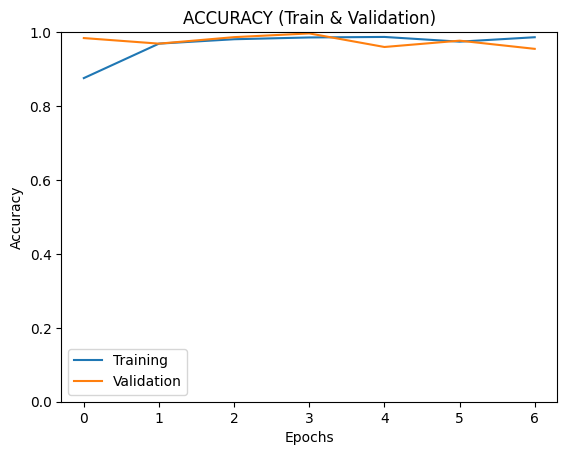

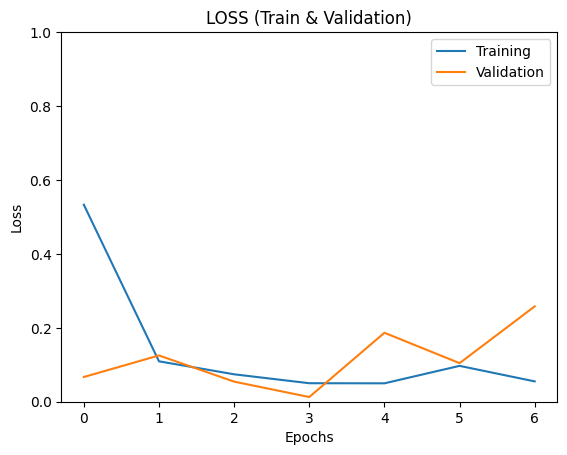

In [28]:
plot_metrics(history, 'accuracy')
plot_metrics(history, 'loss')

# **Predicting**

Predict using the model

Saving Tanjung Gunung_original_50 Tanjung Gunung 1_tiled.jpg_7edb3bb3-37de-42c2-86cc-b1ec2c8388f7.jpg to Tanjung Gunung_original_50 Tanjung Gunung 1_tiled.jpg_7edb3bb3-37de-42c2-86cc-b1ec2c8388f7.jpg


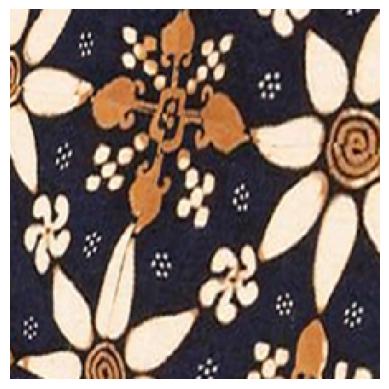

1/1 [==============================] - 3s 3s/step
[1.00]. Tanjung Gunung_original_50 Tanjung Gunung 1_tiled.jpg_7edb3bb3-37de-42c2-86cc-b1ec2c8388f7.jpg is predicted as: Tanjung Gunung


In [36]:
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  path = f"/content/{fn}"
  img = load_img(path, target_size=(224, 224))

  plt.imshow(img)
  plt.axis('off')
  plt.show()

  x = img_to_array(img)
  x = np.expand_dims(x, axis=0)
  x = preprocess_input(x)

  predictions = model.predict(x)
  predicted_class = np.argmax(predictions, axis=1)
  predicted_class_name = class_names[predicted_class[0]]
  confidence = np.max(predictions)

  print(f"[{confidence:.2f}]. {fn} is predicted as: {predicted_class_name}")

# **Confusion Matrix**

Make Test Generator

In [29]:
test_datagen = ImageDataGenerator()

test_generator = test_datagen.flow_from_directory(directory=TEST_DIR,
                                                  batch_size=BATCH_SIZE_TEST,
                                                  class_mode='categorical',
                                                  target_size=(224, 224),
                                                  shuffle=False)

Found 1387 images belonging to 60 classes.


Predict on *test* set

In [30]:
predictions = model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)

11/11 [==============================] - 10s 710ms/step


Draw **Confusion Matrix**

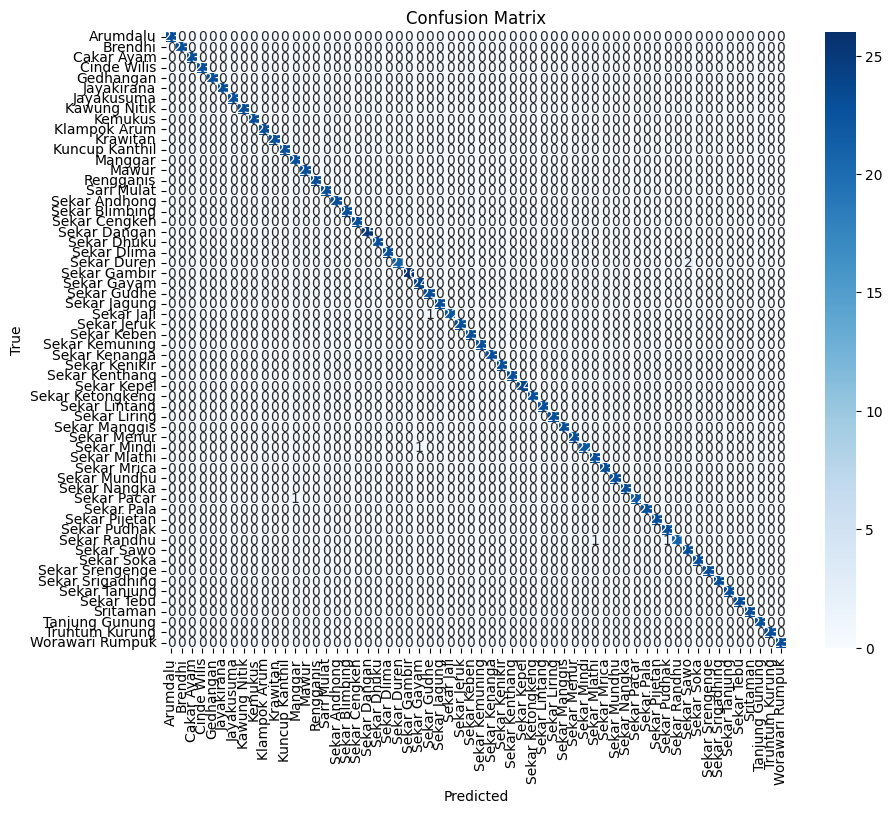

Classification Report:
                   precision    recall  f1-score   support

        Arumdalu       1.00      1.00      1.00        23
         Brendhi       1.00      1.00      1.00        23
      Cakar Ayam       1.00      1.00      1.00        23
     Cinde Wilis       1.00      1.00      1.00        23
       Gedhangan       1.00      1.00      1.00        23
      Jayakirana       1.00      1.00      1.00        23
      Jayakusuma       1.00      1.00      1.00        23
    Kawung Nitik       1.00      1.00      1.00        23
         Kemukus       1.00      1.00      1.00        23
    Klampok Arum       1.00      1.00      1.00        23
        Krawitan       1.00      1.00      1.00        23
  Kuncup Kanthil       1.00      1.00      1.00        23
         Manggar       0.96      1.00      0.98        23
           Mawur       1.00      1.00      1.00        23
       Rengganis       1.00      1.00      1.00        23
      Sari Mulat       1.00      1.00      1.00

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import seaborn as sns

true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

conf_mat = confusion_matrix(true_classes, predicted_classes)

# Generate the classification report
class_report = classification_report(true_classes, predicted_classes, target_names=class_labels)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=90)
plt.yticks(rotation=0)

confusion_matrix_filename = f"cm_{EXPERIMENT_NAME}.png"
plt.savefig(confusion_matrix_filename)

plt.show()

# Display the classification report
print("Classification Report:\n", class_report)

files.download(confusion_matrix_filename)

Print Detailed **Evaluation Matrix**

In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(true_classes, predicted_classes)
precision = precision_score(true_classes, predicted_classes, average='macro')
recall = recall_score(true_classes, predicted_classes, average='macro')
f1 = f1_score(true_classes, predicted_classes, average='macro')

print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")

Accuracy: 0.99
Precision: 1.00
Recall: 0.99
F1-Score: 0.99


Convert model to TFLite

In [33]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

tflite_model_path = f"/content/{EXPERIMENT_NAME}.tflite"

with open(tflite_model_path, "wb") as f:
  f.write(tflite_model)

Download model `TFlite`

In [34]:
from google.colab import files

files.download(tflite_model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download `txt` report

In [35]:
def generate_report(accuracy, precision, recall, f1, elapsed_time, tflite_model_path):
    report_name=f'report_{EXPERIMENT_NAME}.txt'

    model_size = os.path.getsize(tflite_model_path)

    model_size_mb = model_size / (1024 * 1024)

    report_content = (
        f"Accuracy: {accuracy:.4f}\n"
        f"Precision: {precision:.4f}\n"
        f"Recall: {recall:.4f}\n"
        f"F1-Score: {f1:.4f}\n"
        f"Elapsed time: {elapsed_time:.2f} min\n"
        f"Model size: {model_size_mb:.2f} MB\n"
    )

    with open(report_name, "w") as report_file:
        report_file.write(report_content)

    from google.colab import files
    files.download(report_name)

generate_report(accuracy, precision, recall, f1, elapsed_time, tflite_model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>